# Validated Research Agent with LangGraph

A fintech research assistant that answers questions about fraud detection in UPI (India's Unified Payments Interface) payments, and **checks its own work before answering**.


```
                ┌──────────────────────── fail, attempts left: retry with feedback ─┐
                ▼                                                                   │
 question ─▶ research ─────────────▶ validate ─────── pass ──────▶ finalize ─▶ answer
            (ReAct agent:              (citation checks              ▲
             search or answer)          + LLM judge)                 │
                                            └──── fail, no attempts left ┘ (answer marked unverified)

 checkpointer: every turn is saved under a thread_id, so follow-up questions see the conversation
```

| Part | What it shows |
|---|---|
| **1. ReAct agent** | A tool-using agent that decides for itself whether a question needs a web search |
| **2. Validated research graph** | A custom LangGraph graph: researcher → validator → a conditional edge that loops back with feedback when validation fails |
| **3. Conversation memory** | A checkpointer keyed by `thread_id`, so follow-up questions like "which of those..." work, and separate threads stay separate |
| **4. Tool-decision eval** | A labelled test set that measures how often the agent correctly decides to search, compared across Claude and OpenAI |

**Scenario:** a product lead at a fintech startup wants to keep up with real-time fraud-detection methods and regulation for UPI without tracking the news by hand, and needs answers the team can trust.

**Requirements:** a Tavily API key, plus an Anthropic (Claude) **or** OpenAI API key. Part 4 compares both providers if both keys are available, and runs on one otherwise.

## Setup

In [1]:
%pip install -q -U langchain langgraph langchain-tavily langchain-anthropic langchain-openai pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.4/170.4 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 260.4/260.4 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.4/146.4 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 26.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.8/573.8 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 164.6/164.6 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 869.0/869.0 kB 15.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is 

Set `PROVIDER` to `"anthropic"` or `"openai"` for Parts 1-3. Keys come from Colab Secrets (key icon in the left sidebar) or environment variables. **Never paste a key into a cell you save or share.**

In [3]:
import os, getpass

PROVIDER = "anthropic"   # or "openai"

DEFAULT_MODELS = {"anthropic": "claude-sonnet-5-5", "openai": "gpt-5-mini"}
KEY_NAMES = {"anthropic": "ANTHROPIC_API_KEY", "openai": "OPENAI_API_KEY"}


def find_secret(name: str):
    """Colab Secrets first, then an environment variable. Returns None if not set."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    return os.environ.get(name)


def require_secret(name: str) -> str:
    return find_secret(name) or getpass.getpass(f"{name}: ")


os.environ[KEY_NAMES[PROVIDER]] = require_secret(KEY_NAMES[PROVIDER])
os.environ["TAVILY_API_KEY"] = require_secret("TAVILY_API_KEY")

# The other provider is optional: it's only used for the comparison in Part 4
for p, key in KEY_NAMES.items():
    if p != PROVIDER and find_secret(key):
        os.environ[key] = find_secret(key)

AVAILABLE_PROVIDERS = [p for p, key in KEY_NAMES.items() if os.environ.get(key)]
print(f"Main provider: {PROVIDER} ({DEFAULT_MODELS[PROVIDER]})")
print(f"Providers available for the Part 4 comparison: {AVAILABLE_PROVIDERS}")

Main provider: anthropic (claude-sonnet-5-5)
Providers available for the Part 4 comparison: ['anthropic', 'openai']


## Part 1: The ReAct agent
**ReAct** = *reason* about the question, choose an *action* (call a tool or answer), *observe* the result, and repeat until done. `init_chat_model` gives one interface for either provider, and `create_agent` (which replaced LangGraph's deprecated `create_react_agent`) builds the loop.

In [7]:
import json
from datetime import date

from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_tavily import TavilySearch

search_tool = TavilySearch(max_results=5, topic="general")

SYSTEM_PROMPT = f"""You are a research assistant for a fintech product team. Today's date is {date.today():%B %d, %Y}.
- Use the search tool for anything that depends on recent or changing information: news, regulations, products, statistics, who holds a role.
- Answer directly, without searching, when the question doesn't need outside information.
- When you use search results, end each factual claim with (Source: <exact URL from the results>).
- Only state facts that appear in the search results you received."""


def make_llm(provider: str):
    return init_chat_model(f"{provider}:{DEFAULT_MODELS[provider]}")


def make_research_agent(provider: str):
    return create_agent(model=make_llm(provider), tools=[search_tool], system_prompt=SYSTEM_PROMPT)


research_agent = make_research_agent(PROVIDER)

In [8]:
def message_text(content) -> str:
    """Message content is a string (OpenAI) or a list of content blocks (Claude)."""
    if isinstance(content, str):
        return content
    return "".join(block.get("text", "") for block in content if isinstance(block, dict))


def count_searches(messages) -> int:
    return sum(len(m.tool_calls) for m in messages if m.type == "ai" and getattr(m, "tool_calls", None))


def extract_sources(messages) -> dict:
    """Collect {url: {title, content, published}} from every search result in a run."""
    sources = {}
    for m in messages:
        if m.type != "tool":
            continue
        try:
            payload = json.loads(m.content) if isinstance(m.content, str) else m.content
            results = payload.get("results", [])
        except Exception:
            continue
        for r in results:
            if r.get("url"):
                sources[r["url"]] = {"title": r.get("title", ""), "content": r.get("content", ""),
                                     "published": r.get("published_date", "unknown")}
    return sources


def show_run(question: str):
    state = research_agent.invoke({"messages": [{"role": "user", "content": question}]})
    n = count_searches(state["messages"])
    print(f"QUESTION: {question}")
    for m in state["messages"]:
        if m.type == "ai" and getattr(m, "tool_calls", None):
            for call in m.tool_calls:
                print(f"  -> {call['name']}({json.dumps(call['args'])})")
    print("  (no tools used: answered directly)" if n == 0 else f"  {len(extract_sources(state['messages']))} sources retrieved")
    print(f"\nANSWER:\n{message_text(state['messages'][-1].content)}\n" + "-" * 80)


show_run("What are the latest fraud detection methods in UPI systems?")
show_run("What is 2 + 3?")

QUESTION: What are the latest fraud detection methods in UPI systems?
  -> tavily_search({"query": "latest fraud detection methods UPI NPCI", "search_depth": "advanced", "start_date": "2026-01-01"})
  -> tavily_search({"query": "UPI fraud AI machine learning real-time risk scoring banks 2026", "search_depth": "advanced", "start_date": "2026-01-01"})
  -> tavily_search({"query": "RBI UPI fraud new rules mule accounts MuleHunter.AI", "start_date": "2026-01-01"})
  15 sources retrieved

ANSWER:
# Latest fraud detection methods in UPI systems

Several layers are in use, from NPCI's network-level checks to bank-level and device-level controls.

## 1. Real-time AI scoring at the network level (NPCI)
- Every UPI transaction passes through AI fraud models with a 20-millisecond response target. The models can decline a suspicious transaction outright or give feedback to the bank so it can decide. (Source: https://www.zenml.io/llmops-database/ai-powered-fraud-detection-at-national-payment-infras

## Part 2: Validated research graph
The ReAct agent decides *whether* to search, but nothing checks *what it says*. This graph adds a validator:


```
                ┌──────────────────────── fail, attempts left: retry with feedback ─┐
                ▼                                                                   │
 question ─▶ research ─────────────▶ validate ─────── pass ──────▶ finalize ─▶ answer
            (ReAct agent:              (citation checks              ▲
             search or answer)          + LLM judge)                 │
                                            └──── fail, no attempts left ┘ (answer marked unverified)

 checkpointer: every turn is saved under a thread_id, so follow-up questions see the conversation
```

- **research**: runs the ReAct agent. On a retry, it receives its previous answer plus the validator's feedback.
- **validate**: two layers.
  - *Deterministic checks* in plain Python: every cited URL must have actually been retrieved, and an answer built on search results must cite them.
  - An *LLM judge* with structured output: is each claim supported by the source excerpts, and are the sources recent enough for the question?
- **Conditional edge**: pass → finalize; fail with attempts left → back to research; fail with none left → finalize, with the answer clearly marked unverified.

`create_agent` hides this kind of control flow. Building it by hand with `StateGraph` is where LangGraph earns its place.

In [11]:
import re
from typing import Annotated, TypedDict

from pydantic import BaseModel, Field
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import InMemorySaver

MAX_ATTEMPTS = 3
URL_PATTERN = re.compile(r"https?://[^\s)\]>]+")


class ResearchState(TypedDict):
    messages: Annotated[list, add_messages]   # conversation history; persisted by the checkpointer
    question: str
    answer: str
    sources: dict          # url -> source info, for this turn
    attempts: int
    passed: bool
    issues: list
    feedback: str
    trace: list            # human-readable log of this turn


class Verdict(BaseModel):
    passed: bool = Field(description="True only if every factual claim is supported and nothing important is stale")
    issues: list[str] = Field(default_factory=list, description="Specific, fixable problems; empty if passed")


judge_llm = make_llm(PROVIDER).with_structured_output(Verdict)


def deterministic_checks(answer: str, sources: dict) -> list[str]:
    issues = []
    cited = {u.rstrip(".,;") for u in URL_PATTERN.findall(answer)}
    unknown = sorted(u for u in cited if u not in sources)
    if unknown:
        issues.append("Cites URLs that were never retrieved: " + ", ".join(unknown))
    if sources and not cited:
        issues.append("Uses search results but cites no sources; add (Source: URL) to each factual claim.")
    return issues


def format_sources(sources: dict, limit: int = 10, chars: int = 800) -> str:
    if not sources:
        return "(no web sources were retrieved)"
    return "\n\n".join(f"URL: {u}\nTitle: {s['title']}\nPublished: {s['published']}\nExcerpt: {s['content'][:chars]}"
                        for u, s in list(sources.items())[:limit])


def format_history(messages, turns: int = 4) -> str:
    recent = messages[-(turns * 2):]
    return "\n".join(f"{m.type.upper()}: {message_text(m.content)[:600]}" for m in recent) or "(none)"


# ---------------- nodes ----------------
def research(state: ResearchState) -> dict:
    attempt = state["attempts"] + 1
    prompt = state["question"]
    if state["feedback"]:
        prompt += ("\n\nA reviewer rejected your previous answer.\n"
                   f"PREVIOUS ANSWER:\n{state['answer']}\n\nISSUES TO FIX:\n{state['feedback']}\n\n"
                   "Write a corrected answer that fixes every issue. Search again if you need better sources.")
    history = state["messages"][:-1]   # earlier turns; the last message is this turn's question
    result = research_agent.invoke({"messages": history + [HumanMessage(prompt)]})
    new_sources = extract_sources(result["messages"])
    return {
        "attempts": attempt,
        "answer": message_text(result["messages"][-1].content),
        "sources": {**state["sources"], **new_sources},
        "trace": state["trace"] + [f"research  attempt {attempt}: {count_searches(result['messages'])} searches, "
                                   f"{len(new_sources)} new sources"],
    }


def validate(state: ResearchState) -> dict:
    issues = deterministic_checks(state["answer"], state["sources"])
    verdict = judge_llm.invoke(
        f"""You are a strict fact-checking reviewer. Today's date is {date.today():%B %d, %Y}.
Decide whether the ANSWER can be trusted, judging ONLY against the SOURCES below.
- Every factual claim about the world must be supported by a source excerpt. Flag each unsupported claim.
- If the question asks for recent or current information, flag sources that are clearly outdated.
- If the question needs no outside information (math, definitions, general reasoning), pass it.
- Do not flag style. List only specific, fixable problems.

CONVERSATION SO FAR:
{format_history(state["messages"][:-1])}

QUESTION: {state["question"]}

ANSWER:
{state["answer"]}

SOURCES:
{format_sources(state["sources"])}""")
    if not verdict.passed:
        issues += verdict.issues or ["The reviewer rejected the answer without giving specifics."]
    passed = not issues
    return {
        "passed": passed,
        "issues": issues,
        "feedback": "\n".join(f"- {i}" for i in issues),
        "trace": state["trace"] + [f"validate  attempt {state['attempts']}: "
                                   + ("PASS" if passed else f"FAIL ({len(issues)} issues)")]
                 + [f"            - {i}" for i in issues],
    }


def finalize(state: ResearchState) -> dict:
    text = state["answer"]
    if not state["passed"]:
        text += (f"\n\n> **Not fully verified** after {state['attempts']} attempts. Outstanding issues:\n"
                 + "\n".join(f"> - {i}" for i in state["issues"]))
    return {"messages": [AIMessage(text)],
            "trace": state["trace"] + ["finalize  " + ("verified" if state["passed"] else "marked unverified")]}


# ---------------- routing ----------------
def route_after_validation(state: ResearchState) -> str:
    if state["passed"]:
        return "finalize"
    return "research" if state["attempts"] < MAX_ATTEMPTS else "finalize"


builder = StateGraph(ResearchState)
builder.add_node("research", research)
builder.add_node("validate", validate)
builder.add_node("finalize", finalize)
builder.add_edge(START, "research")
builder.add_edge("research", "validate")
builder.add_conditional_edges("validate", route_after_validation, {"research": "research", "finalize": "finalize"})
builder.add_edge("finalize", END)

graph = builder.compile(checkpointer=InMemorySaver())   # the checkpointer powers Part 3

/usr/local/lib/python3.13/dist-packages/langchain_anthropic/chat_models.py:2975: UserWarning: You are attempting to use structured output via forced tool calling, which is not supported when `thinking` is enabled or on claude-sonnet-5-5. This method will raise an OutputParserException if tool calls are not generated. Consider `method='json_schema'`, disabling `thinking` where supported, or adjusting your prompt to ensure the tool is called.
  llm = self._get_llm_for_structured_output_when_thinking_is_enabled(


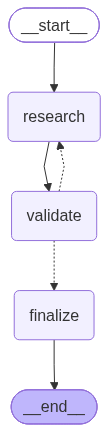

In [12]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:  # rendering uses an online service and can fail offline
    print("Couldn't render the graph image:", e)
    print(graph.get_graph().draw_mermaid())

In [13]:
def ask(question: str, thread_id: str):
    """Run one turn of the conversation on a thread and print the trace and answer."""
    config = {"configurable": {"thread_id": thread_id}}
    out = graph.invoke({
        "messages": [HumanMessage(question)], "question": question, "answer": "",
        "sources": {}, "attempts": 0, "passed": False, "issues": [], "feedback": "", "trace": [],
    }, config)
    print(f"[thread {thread_id}] QUESTION: {question}\n")
    print("\n".join("  " + line for line in out["trace"]))
    print(f"\nANSWER:\n{message_text(out['messages'][-1].content)}\n" + "=" * 80)
    return out


turn_1 = ask("What are the latest fraud detection methods being used in UPI systems?", thread_id="pm-1")

[thread pm-1] QUESTION: What are the latest fraud detection methods being used in UPI systems?

  research  attempt 1: 3 searches, 13 new sources
  validate  attempt 1: FAIL (5 issues)
              - Section 1: The ZenML excerpt supports only the real-time 20 ms AI scoring and the decline-or-feedback behaviour. It says nothing about Kafka streaming pipelines, open-source technology, or language models fine-tuned for Indian financial contexts that handle transaction patterns and customer disputes. These claims are unsupported.
              - Section 5: The claim about the DoT Financial Fraud Risk Indicator cites a DDNews Facebook post. No excerpt from that URL appears in the sources, so the claim is unsupported. The answer says it saw a snippet, but no such snippet is provided.
              - Section 7: The claims about an RBI authentication mandate and liability shifting to receiving banks cite a LexisNexis page. No excerpt from that URL appears in the sources, so both claims are un

If the trace shows a `FAIL` followed by another research attempt, that's the loop working: the validator found specific problems (an unsupported claim, a missing citation, a stale source) and sent them back for a fix. If it still can't pass after `MAX_ATTEMPTS`, the answer is delivered but clearly labelled, rather than silently presented as trustworthy.

## Part 3: Conversation memory
The graph was compiled with a **checkpointer**, which saves the state after every turn under a `thread_id`. A follow-up on the same thread sees the earlier conversation; the same follow-up on a new thread doesn't.

In [14]:
turn_2 = ask("Which of those are required by RBI or NPCI rather than optional?", thread_id="pm-1")

[thread pm-1] QUESTION: Which of those are required by RBI or NPCI rather than optional?

  research  attempt 1: 4 searches, 20 new sources
  validate  attempt 1: FAIL (7 issues)
              - The whole 'DoT Financial Fraud Risk Indicator (FRI)' section is unsupported. The PIB page PRID=2141616 and the Zigram article are not in the SOURCES. That covers the 30 June 2025 RBI advisory, the list of bank types, and the 'not optional for many regulated institutions' quote.
              - The whole 'MuleHunter.AI' section is unsupported. The Times of India, ETBFSI and PIB PRID=2244478 pages are not in the SOURCES. That covers the Department of Financial Services direction, the 'nudging' and 'free for banks' claims, the '26 banks' figure, and the RBI advisories on real-time monitoring and network analytics.
              - The beneficiary-name claim is not supported by the cited NPCI Consolidated Circular excerpt. The excerpt only shows clauses 7.7 and 2.8. The 'shall ensure' quote and the 

In [15]:
# The same follow-up on a brand-new thread has no idea what "those" refers to
fresh = ask("Which of those are required by RBI or NPCI rather than optional?", thread_id="pm-2")

[thread pm-2] QUESTION: Which of those are required by RBI or NPCI rather than optional?

  research  attempt 1: 0 searches, 0 new sources
  validate  attempt 1: PASS
  finalize  verified

ANSWER:
I can't tell what "those" refers to, because this is the start of our conversation and I don't see an earlier list. Could you paste the list, or tell me which topic you mean? For example:

- UPI features, such as UPI Lite, credit on UPI, or autopay mandates
- Security or authentication measures, such as two-factor authentication, tokenization, or device binding
- Compliance items, such as KYC, data localization, or grievance redressal
- Product features for a payment aggregator, a PPI, or a lending app

Once I know the list, I'll check current RBI and NPCI circulars and master directions. For each item, I'll mark whether it's mandatory, conditional (for example, only for certain entity types or transaction thresholds), or optional. I'll cite the source for each.


In [16]:
for tid in ("pm-1", "pm-2"):
  saved = graph.get_state({"configurable": {"thread_id": tid}}).values["messages"]
  print(f"thread {tid}: {len(saved)} messages saved ({len(saved) // 2} turns)")

thread pm-1: 4 messages saved (2 turns)
thread pm-2: 2 messages saved (1 turns)


`InMemorySaver` keeps threads only while the notebook is running. In production you'd swap in a persistent checkpointer such as SQLite or Postgres, with no other code changes.

## Part 4: Evaluating the tool decision
Parts 1-3 show the agent working on hand-picked questions. This part **measures** it. Each question is labelled with whether answering it well requires a web search, and the agent's actual choice is compared with the label.

The two error types have different costs:
- **Missed search** (should have searched, didn't): the agent answers from training data that may be stale. This is the dangerous error.
- **Unnecessary search** (searched when it didn't need to): costs time and money, but the answer is usually still fine.

This evaluates the plain ReAct agent from Part 1, since that's where the decision is made.

In [17]:
EVAL_SET = [
    # (question, needs_search)
    ("What is the latest RBI circular on UPI fraud prevention?", True),
    ("What is the current daily transaction limit for UPI payments?", True),
    ("What did NPCI announce about UPI in the last month?", True),
    ("Who is the current Governor of the Reserve Bank of India?", True),
    ("How many UPI transactions were processed last month?", True),
    ("What new UPI scams have been reported this year?", True),
    ("Which banks have launched AI-based UPI fraud detection recently?", True),
    ("What is the current RBI repo rate?", True),
    ("What is 2 + 3?", False),
    ("Explain the difference between precision and recall in fraud detection.", False),
    ("What does a false positive mean for a payment fraud model?", False),
    ("Write a regular expression that matches a 10-digit Indian mobile number.", False),
    ("Convert 2,500 rupees to paise.", False),
    ("Why is class imbalance a problem when training fraud classifiers?", False),
    ("Explain what a graph neural network is in two sentences.", False),
    ("Suggest three names for an internal fraud-alert dashboard.", False),
]
print(f"{len(EVAL_SET)} questions: {sum(n for _, n in EVAL_SET)} need search, {sum(not n for _, n in EVAL_SET)} don't")

16 questions: 8 need search, 8 don't


In [18]:
import time
import pandas as pd

RUN_EVAL = True   # makes one agent call per question per provider

def run_tool_decision_eval(provider: str) -> pd.DataFrame:
    agent = make_research_agent(provider)
    rows = []
    for question, needs_search in EVAL_SET:
        t0 = time.perf_counter()
        try:
            state = agent.invoke({"messages": [{"role": "user", "content": question}]})
            searched, error = count_searches(state["messages"]) > 0, ""
        except Exception as e:
            searched, error = None, str(e)[:80]
        rows.append({"provider": provider, "question": question, "needs_search": needs_search,
                     "searched": searched, "seconds": round(time.perf_counter() - t0, 1), "error": error})
        print(f"  {provider:<9} {'search' if searched else 'direct' if searched is not None else 'ERROR':<7} {question[:60]}")
    return pd.DataFrame(rows)

if RUN_EVAL:
    eval_df = pd.concat([run_tool_decision_eval(p) for p in AVAILABLE_PROVIDERS], ignore_index=True)

  anthropic search  What is the latest RBI circular on UPI fraud prevention?
  anthropic search  What is the current daily transaction limit for UPI payments
  anthropic search  What did NPCI announce about UPI in the last month?
  anthropic search  Who is the current Governor of the Reserve Bank of India?
  anthropic search  How many UPI transactions were processed last month?
  anthropic search  What new UPI scams have been reported this year?
  anthropic search  Which banks have launched AI-based UPI fraud detection recen
  anthropic search  What is the current RBI repo rate?
  anthropic direct  What is 2 + 3?
  anthropic direct  Explain the difference between precision and recall in fraud
  anthropic direct  What does a false positive mean for a payment fraud model?
  anthropic direct  Write a regular expression that matches a 10-digit Indian mo
  anthropic direct  Convert 2,500 rupees to paise.
  anthropic direct  Why is class imbalance a problem when training fraud classif
  anth

In [19]:
def summarize(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for provider, g in df.groupby("provider"):
        ok = g[g["searched"].notna()]
        searched = ok["searched"].astype(bool)
        needs = ok["needs_search"].astype(bool)
        rows.append({
            "provider": provider,
            "accuracy": f"{(searched == needs).mean():.0%}" if len(ok) else "n/a",
            "missed searches": int((needs & ~searched).sum()),
            "unnecessary searches": int((~needs & searched).sum()),
            "avg seconds": round(ok["seconds"].mean(), 1) if len(ok) else None,
            "errors": int(g["searched"].isna().sum()),
        })
    return pd.DataFrame(rows).set_index("provider")

if RUN_EVAL:
    display(summarize(eval_df))
    wrong = eval_df[eval_df["searched"].notna() & (eval_df["searched"].astype(bool) != eval_df["needs_search"])]
    print("\nMisclassified questions:")
    print("(none)" if wrong.empty else wrong[["provider", "question", "needs_search", "searched"]].to_string(index=False))

,accuracy,missed searches,unnecessary searches,avg seconds,errors
provider,,,,,
anthropic,100%,0,0,8.3,0
openai,100%,0,0,18.5,0



Misclassified questions:
(none)


**Reading the results.** Look at the misclassified questions, not just the accuracy. A model that skips the search for *"Who is the current RBI Governor?"* will confidently state whoever held the role in its training data. The fix is usually in the system prompt (for example, naming "who holds a role" explicitly as a reason to search), and this eval tells you whether a prompt change actually helped.

## Takeaways
- **Prebuilt agents hide control flow; custom graphs expose it.** The validator loop, retry limit and "unverified" path are explicit, inspectable edges.
- **Validation works best in layers.** Cheap deterministic checks catch invented URLs; the LLM judge catches unsupported claims and stale sources.
- **Memory is a checkpointer plus a thread ID.** The graph code doesn't change; persistence is configuration.
- **Measure agent decisions.** Two hand-picked examples prove nothing; a labelled set turns "it seems to work" into a number you can improve.

## Limitations
- The judge is the same model family as the researcher by default; a different provider as judge would be a stronger check.
- The judge sees search *excerpts*, not full pages, so it can reject claims that are supported elsewhere on the page.
- 16 questions is a small eval set, and a few labels are judgement calls; treat differences of one or two questions as noise.
- `InMemorySaver` forgets everything when the notebook restarts.